# 01 — Data Understanding & EDA : dataset CarDD

**Projet AutoDamage ML** — classification des zones endommagées d'un véhicule (Machine Learning classique).

Objectifs de ce notebook :
1. Vérifier la structure des fichiers et le format COCO.
2. Comprendre `image_info.xlsx` et le confronter aux JSON.
3. Décrire les classes, leur répartition et le déséquilibre.
4. Étudier les dimensions des images et la géométrie des bounding boxes.
5. Visualiser des images annotées et les régions (crops) qui seront classifiées.

> Aucun fichier du dataset n'est modifié. Tous les nombres affichés sont **calculés** à partir des fichiers présents.
> Le code de lecture est dans `src/data/` pour être réutilisé dans les phases suivantes.

In [1]:
import sys
from pathlib import Path

# Rendre le package `src` importable depuis notebooks/
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image

from src.data.coco_loader import (
    DATASET_ROOT, SPLITS, annotation_path, image_dir,
    load_coco_json, load_all_splits, add_bbox_features, load_image_info,
)
from src.data.image_io import read_image_rgb

pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# Couleur fixe par classe (palette catégorielle validée daltonisme ; ordre = id COCO)
CLASS_ORDER = ["dent", "scratch", "crack", "glass shatter", "lamp broken", "tire flat"]
CLASS_COLORS = dict(zip(CLASS_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
SPLIT_COLORS = {"train": "#1c5cab", "val": "#6da7ec", "test": "#b7d3f6"}
print("Dataset :", DATASET_ROOT)

Dataset : C:\Users\MSI\Desktop\ML_project\dataset\CarDD_COCO


## 1. Structure des fichiers sur disque

In [2]:
rows = []
for split in SPLITS:
    files = sorted(image_dir(split).iterdir())
    exts = pd.Series([f.suffix.lower() for f in files]).value_counts().to_dict()
    rows.append({"split": split, "dossier": image_dir(split).name, "n_fichiers": len(files),
                 "extensions": exts, "json": annotation_path(split).name,
                 "taille_json_Mo": round(annotation_path(split).stat().st_size / 1e6, 1)})
disk = pd.DataFrame(rows)
disk

,split,dossier,n_fichiers,extensions,json,taille_json_Mo
0,train,train2017,2816,{'.jpg': 2816},instances_train2017.json,20.5
1,val,val2017,810,{'.jpg': 810},instances_val2017.json,6.0
2,test,test2017,374,{'.jpg': 374},instances_test2017.json,2.7


**Interprétation.** Les trois dossiers attendus (`train2017`, `val2017`, `test2017`) existent et ne contiennent que des fichiers `.jpg`.
Chaque split possède son fichier d'annotations COCO. Le découpage train/val/test est **fourni par les auteurs** : nous le respecterons tel quel.

## 2. Vérification du format COCO

In [3]:
for split in SPLITS:
    coco = load_coco_json(split)
    print(f"{split:5s} | clés : {list(coco.keys())} | images={len(coco['images'])} | annotations={len(coco['annotations'])}")

coco_train = load_coco_json("train")
print("\ninfo     :", coco_train["info"])
print("licenses :", coco_train["licenses"])
print("\nExemple d'image      :", coco_train["images"][0])
ex = dict(coco_train["annotations"][0]); ex["segmentation"] = str(ex["segmentation"])[:70] + "..."
print("Exemple d'annotation :", ex)

train | clés : ['licenses', 'info', 'categories', 'images', 'annotations'] | images=2816 | annotations=6211
val   | clés : ['licenses', 'info', 'categories', 'images', 'annotations'] | images=810 | annotations=1744
test  | clés : ['licenses', 'info', 'categories', 'images', 'annotations'] | images=374 | annotations=785

info     : {'contributor': 'Xinkuang Wang, Wenjing Li, Zhongcheng Wu', 'date_created': '2022.05.01', 'description': 'CarDD for car damage detection in COCO Format.', 'url': 'https://cardd-ustc.github.io/', 'version': 'v1.0'}
licenses : [{'name': 'CarDD', 'id': 0, 'url': 'https://cardd-ustc.github.io/'}]

Exemple d'image      : {'id': 1, 'width': 1000, 'height': 750, 'file_name': '000001.jpg', 'license': 0}
Exemple d'annotation : {'id': 1, 'image_id': 1, 'category_id': 2, 'segmentation': '[[233.35, 46.65, 217.25, 58.24, 210.82, 65.97, 204.38, 78.2, 197.3, 93...', 'area': 13584.0, 'bbox': [167.04, 40.21, 202.79, 131.34], 'iscrowd': 0, 'attributes': {'occluded': False}}


In [4]:
images, annotations, categories = load_all_splits()   # lève une erreur si les catégories diffèrent entre splits
annotations = add_bbox_features(annotations, images)
print("Catégories (identiques dans les 3 splits) :")
categories

Catégories (identiques dans les 3 splits) :


,category_id,category_name
0,1,dent
1,2,scratch
2,3,crack
3,4,glass shatter
4,5,lamp broken
5,6,tire flat


In [5]:
# Contrôles structurels rapides (le nettoyage détaillé sera fait en phase 2)
checks = {
    "ids d'image uniques sur les 3 splits": images["id"].is_unique,
    "file_name uniques sur les 3 splits": images["file_name"].is_unique,
    "ids d'annotation uniques par split": annotations.groupby("split")["id"].apply(lambda s: s.is_unique).all(),
    "toutes les category_id sont connues": annotations["category_name"].notna().all(),
    "toutes les annotations pointent vers une image": annotations["img_w"].notna().all(),
    "type de segmentation": annotations["segmentation"].map(lambda s: type(s).__name__).value_counts().to_dict(),
    "valeurs iscrowd": annotations["iscrowd"].value_counts().to_dict(),
    "valeurs attributes": annotations["attributes"].astype(str).value_counts().to_dict(),
}
for k, v in checks.items():
    print(f"{k:45s} -> {v}")

ids d'image uniques sur les 3 splits          -> True
file_name uniques sur les 3 splits            -> True
ids d'annotation uniques par split            -> True
toutes les category_id sont connues           -> True
toutes les annotations pointent vers une image -> True
type de segmentation                          -> {'list': 8740}
valeurs iscrowd                               -> {0: 8740}
valeurs attributes                            -> {"{'occluded': False}": 8740}


**Interprétation.** Les trois fichiers respectent la structure COCO (`info`, `licenses`, `categories`, `images`, `annotations`).
- `bbox` suit la convention COCO `[x, y, largeur, hauteur]` en pixels.
- Les segmentations sont des **polygones** (listes), aucune n'est en RLE et `iscrowd` vaut toujours 0 : chaque annotation est une instance individuelle.
- L'attribut `occluded` vaut toujours `False` : il n'apporte aucune information.
- Les identifiants d'image sont uniques **sur l'ensemble** des trois splits (ils correspondent à la numérotation globale 1–4000).
- Pour notre projet, chaque **annotation** (et non chaque image) deviendra un échantillon : la région de la bounding box sera découpée puis classifiée.

## 3. Le fichier `image_info.xlsx`

In [6]:
info = load_image_info()
print(info.shape)
display(info.head())
display(info.describe(include="all").T)
print("Valeurs manquantes :"); print(info.isna().sum()[info.isna().sum() > 0])

(4000, 10)


,id,file_name,width,height,file_size_kb,n_instances,n_categories,shooting_angle,complete_or_partial,color
0,1,000001.jpg,1000,750,1114,2,2,side,partial,red
1,2,000002.jpg,1000,667,637,1,1,side,partial,white
2,3,000003.jpg,1000,667,966,1,1,side,partial,white
3,4,000004.jpg,1000,667,806,1,1,side,partial,gray
4,5,000005.jpg,1000,667,959,1,1,side,partial,gray


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,4000.0,NaN,NaN,NaN,2000.5,1154.844867,1.0,1000.75,2000.5,3000.25,4000.0
file_name,4000,4000,000001.jpg,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
width,4000.0,NaN,NaN,NaN,978.0585,79.594095,562.0,1000.0,1000.0,1000.0,1000.0
height,4000.0,NaN,NaN,NaN,706.17275,97.850087,333.0,667.0,667.0,750.0,1000.0
file_size_kb,4000.0,NaN,NaN,NaN,738.51525,180.778984,174.0,617.0,728.0,850.0,1824.0
n_instances,4000.0,NaN,NaN,NaN,2.185,1.533415,1.0,1.0,2.0,3.0,13.0
n_categories,4000.0,NaN,NaN,NaN,1.538,0.790704,1.0,1.0,1.0,2.0,5.0
shooting_angle,3560,4,side,1622,NaN,NaN,NaN,NaN,NaN,NaN,NaN
complete_or_partial,4000,2,partial,3920,NaN,NaN,NaN,NaN,NaN,NaN,NaN
color,3656,14,silver,1008,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Valeurs manquantes :
shooting_angle    440
color             344
dtype: int64


In [7]:
# Cohérence xlsx <-> JSON
m = images.merge(info, on="file_name", how="outer", suffixes=("_json", "_xlsx"), indicator=True)
print("Correspondance des file_name :", m["_merge"].value_counts().to_dict())
both = m[m["_merge"] == "both"]
print("Même id               :", (both["id_json"] == both["id_xlsx"]).all())
print("Mêmes dimensions      :", ((both["width_json"] == both["width_xlsx"]) & (both["height_json"] == both["height_xlsx"])).all())

n_inst = annotations.groupby("image_id").size().rename("n_json")
n_cat = annotations.groupby("image_id")["category_id"].nunique().rename("ncat_json")
cmp = info.set_index("id")[["n_instances", "n_categories"]].join(n_inst).join(n_cat)
print("#instances identique  :", (cmp["n_instances"] == cmp["n_json"]).all())
print("#categories identique :", (cmp["n_categories"] == cmp["ncat_json"]).all())

Correspondance des file_name : {'both': 4000, 'left_only': 0, 'right_only': 0}
Même id               : True
Mêmes dimensions      : True
#instances identique  : True
#categories identique : True


**Interprétation.** `image_info.xlsx` contient une ligne par image (4000) avec des métadonnées fournies par les auteurs :
dimensions, taille du fichier, nombre d'instances et de catégories, **angle de prise de vue**, vue **complète ou partielle** du véhicule, et **couleur** de la carrosserie.
Les colonnes communes (id, nom de fichier, dimensions, nombre d'instances/catégories) sont **parfaitement cohérentes** avec les JSON.
Remarques :
- La colonne originale s'appelle `"complete or partial "` (espace final) : `load_image_info()` normalise les noms sans modifier le fichier.
- `shooting angle` et `color` contiennent des valeurs manquantes (voir ci-dessus) : ce sont des métadonnées descriptives, **pas des variables d'entrée** de notre modèle (l'application ne connaîtra que l'image recadrée).

## 4. Volume : images et annotations par split

In [8]:
vol = pd.DataFrame({
    "images": images.groupby("split").size(),
    "annotations": annotations.groupby("split").size(),
}).loc[list(SPLITS)]
vol["annot_par_image"] = (vol["annotations"] / vol["images"]).round(2)
vol["%_images"] = (100 * vol["images"] / vol["images"].sum()).round(1)
vol.loc["total"] = [vol["images"].sum(), vol["annotations"].sum(),
                    round(vol["annotations"].sum() / vol["images"].sum(), 2), 100.0]
vol

,images,annotations,annot_par_image,%_images
split,,,,
train,2816,6211,2.21,70.4
val,810,1744,2.15,20.2
test,374,785,2.10,9.4
total,4000,8740,2.18,100.0


**Interprétation.** Le dataset contient 4000 images et 8740 annotations. Le découpage est d'environ 70 % / 20 % / 10 %.
Comme une image contient en moyenne un peu plus de deux dommages, nous disposerons d'environ **6200 régions d'entraînement**, ce qui est un volume confortable pour KNN, SVM et Random Forest.

## 5. Répartition des classes

In [9]:
counts = pd.crosstab(annotations["category_name"], annotations["split"]).loc[CLASS_ORDER, list(SPLITS)]
pct = (100 * counts / counts.sum()).round(1)
display(counts.assign(total=counts.sum(axis=1)))
print("Pourcentage par split :"); display(pct)

split,train,val,test,total
category_name,,,,
dent,1806,501,236,2543
scratch,2560,728,307,3595
crack,651,177,70,898
glass shatter,475,135,71,681
lamp broken,494,141,69,704
tire flat,225,62,32,319


Pourcentage par split :


split,train,val,test
category_name,,,
dent,29.1,28.7,30.1
scratch,41.2,41.7,39.1
crack,10.5,10.1,8.9
glass shatter,7.6,7.7,9.0
lamp broken,8.0,8.1,8.8
tire flat,3.6,3.6,4.1


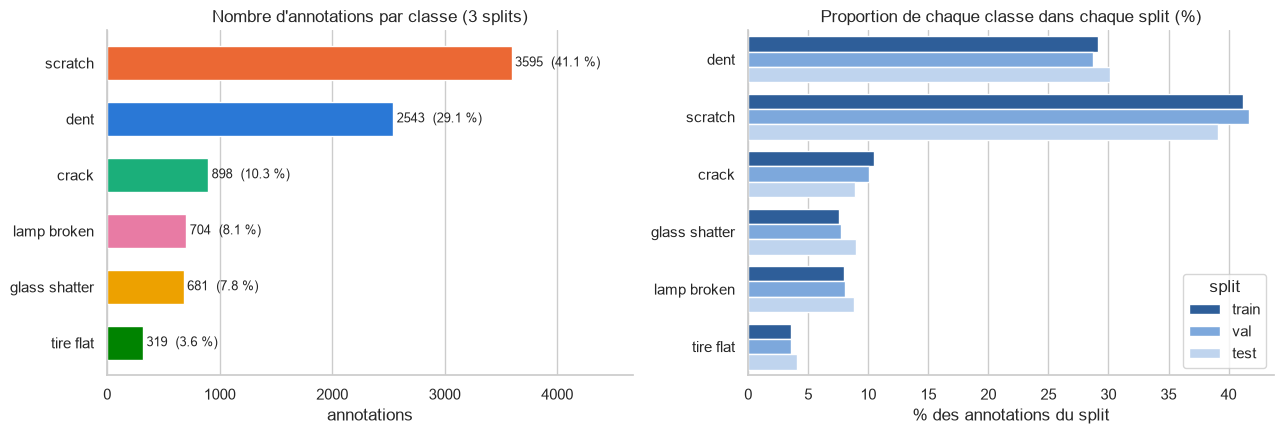

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

tot = counts.sum(axis=1).sort_values()
axes[0].barh(tot.index, tot.values, color=[CLASS_COLORS[c] for c in tot.index], height=0.6)
for y, v in enumerate(tot.values):
    axes[0].text(v + 30, y, f"{v}  ({100*v/tot.sum():.1f} %)", va="center", fontsize=9)
axes[0].set_title("Nombre d'annotations par classe (3 splits)")
axes[0].set_xlabel("annotations"); axes[0].set_xlim(0, tot.max() * 1.3)
axes[0].grid(axis="y", visible=False)

pct_long = pct.reset_index().melt(id_vars="category_name", var_name="split", value_name="pct")
sns.barplot(data=pct_long, y="category_name", x="pct", hue="split", order=CLASS_ORDER,
            palette=SPLIT_COLORS, ax=axes[1], edgecolor="white", linewidth=1)
axes[1].set_title("Proportion de chaque classe dans chaque split (%)")
axes[1].set_xlabel("% des annotations du split"); axes[1].set_ylabel("")
axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Interprétation.**
- **scratch** (≈ 41 %) et **dent** (≈ 29 %) représentent à elles deux environ 70 % des annotations.
- **tire flat** est la classe la plus rare (≈ 3,6 %), suivie de glass shatter, lamp broken et crack (≈ 8–10 % chacune).
- Les proportions sont **très proches dans les trois splits** : le découpage officiel est quasi stratifié, ce qui rend les scores de validation et de test représentatifs.

## 6. Analyse du déséquilibre

In [11]:
tr = counts["train"]
imbalance = pd.DataFrame({"train": tr, "% train": (100 * tr / tr.sum()).round(1),
                          "ratio vs majoritaire": (tr.max() / tr).round(2)}).sort_values("train", ascending=False)
display(imbalance)
print(f"Ratio de déséquilibre (max/min) sur train : {tr.max() / tr.min():.1f}")
print(f"Accuracy d'un classifieur naïf qui prédit toujours '{tr.idxmax()}' (sur test) : "
      f"{counts.loc[tr.idxmax(), 'test'] / counts['test'].sum():.3f}")

,train,% train,ratio vs majoritaire
category_name,,,
scratch,2560,41.2,1.00
dent,1806,29.1,1.42
crack,651,10.5,3.93
lamp broken,494,8.0,5.18
glass shatter,475,7.6,5.39
tire flat,225,3.6,11.38


Ratio de déséquilibre (max/min) sur train : 11.4
Accuracy d'un classifieur naïf qui prédit toujours 'scratch' (sur test) : 0.391


**Interprétation.** Le rapport entre la classe majoritaire (scratch) et la minoritaire (tire flat) dépasse 11 sur le train.
Conséquences pour la suite :
1. L'**accuracy seule est trompeuse** : un modèle qui répond toujours « scratch » obtiendrait déjà ≈ 39 % sur le test. Nous utiliserons le **F1 macro** comme métrique principale, avec le F1 par classe.
2. Ce classifieur naïf servira de **baseline** (`DummyClassifier`) en phase 4.
3. Nous testerons `class_weight="balanced"` pour SVM et Random Forest (KNN ne le supporte pas directement).
4. Pas de sur-échantillonnage aveugle : les classes rares restent nombreuses en valeur absolue (225 régions *tire flat* en train).

## 7. Annotations par image et co-occurrence des dommages

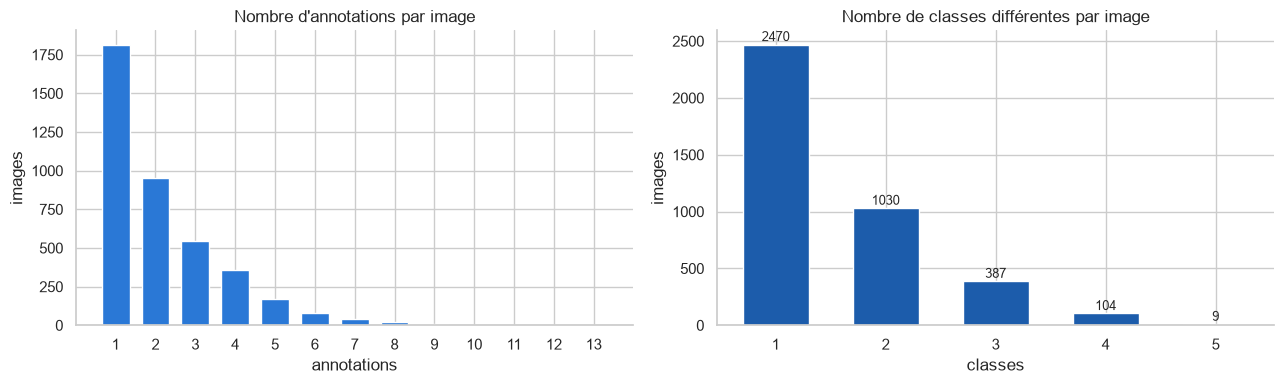

       n_annot  n_classes
count  4000.00    4000.00
mean      2.18       1.54
std       1.53       0.79
min       1.00       1.00
25%       1.00       1.00
50%       2.00       1.00
75%       3.00       2.00
max      13.00       5.00


In [12]:
per_img = annotations.groupby("image_id").agg(n_annot=("id", "size"), n_classes=("category_id", "nunique"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
vc = per_img["n_annot"].value_counts().sort_index()
axes[0].bar(vc.index, vc.values, color="#2a78d6", width=0.7)
axes[0].set_title("Nombre d'annotations par image"); axes[0].set_xlabel("annotations"); axes[0].set_ylabel("images")
axes[0].set_xticks(vc.index)
vc2 = per_img["n_classes"].value_counts().sort_index()
axes[1].bar(vc2.index, vc2.values, color="#1c5cab", width=0.6)
for x, v in zip(vc2.index, vc2.values):
    axes[1].text(x, v + 30, str(v), ha="center", fontsize=9)
axes[1].set_title("Nombre de classes différentes par image"); axes[1].set_xlabel("classes"); axes[1].set_ylabel("images")
plt.tight_layout(); plt.show()
print(per_img.describe().round(2))

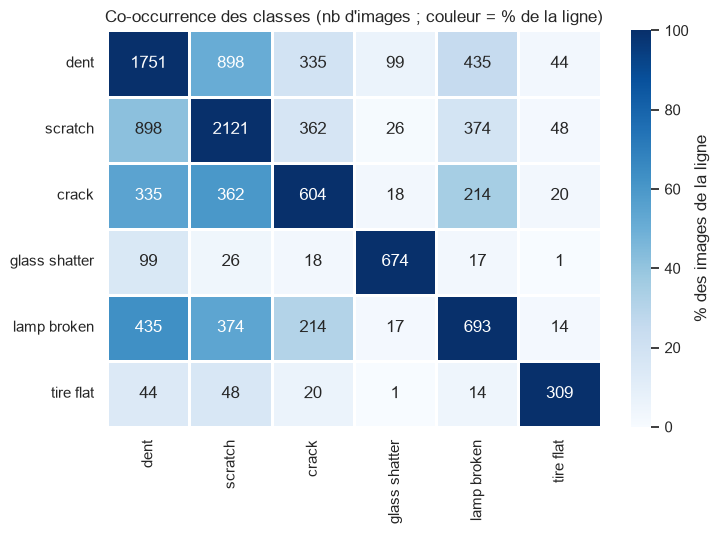

In [13]:
presence = pd.crosstab(annotations["image_id"], annotations["category_name"]).clip(upper=1)[CLASS_ORDER]
co = presence.T @ presence     # diagonale = nb d'images contenant la classe
co_pct = (100 * co / np.diag(co)[:, None]).round(0)   # % des images de la ligne contenant aussi la colonne
plt.figure(figsize=(7.5, 5.5))
sns.heatmap(co_pct, annot=co.values, fmt="d", cmap="Blues", cbar_kws={"label": "% des images de la ligne"},
            linewidths=2, linecolor="white")
plt.title("Co-occurrence des classes (nb d'images ; couleur = % de la ligne)")
plt.xlabel(""); plt.ylabel(""); plt.tight_layout(); plt.show()

**Interprétation.**
- La majorité des images ne contient qu'**une seule classe** de dommage, mais une part importante en contient deux ou plus (jusqu'à 13 annotations sur une image).
- Les dommages de carrosserie se combinent souvent : **dent + scratch** est la paire la plus fréquente (898 images) ; une image avec *crack* contient aussi une *scratch* dans ≈ 60 % des cas et une *dent* dans ≈ 55 % ; une image avec *lamp broken* contient une *dent* dans ≈ 63 % des cas.
- À l'inverse, **glass shatter** et **tire flat** sont majoritairement isolés (≈ 85 % de leurs images ne contiennent pas de *dent*, et les autres associations sont encore plus rares).
- Conséquence : il serait impossible de donner **une seule étiquette par image**. C'est pourquoi l'application demande à l'utilisateur de **recadrer une zone**, et nous classifierons des **régions** (une par annotation).

## 8. Dimensions et résolution des images

In [14]:
# Vérification des dimensions RÉELLES (lecture de l'en-tête de chaque fichier, sans décoder les pixels)
real = []
for r in images.itertuples():
    with Image.open(image_dir(r.split) / r.file_name) as im:
        real.append((im.size[0], im.size[1], im.mode, im.format))
images[["real_w", "real_h", "mode", "format"]] = pd.DataFrame(real, index=images.index)
print("Dimensions réelles == dimensions déclarées :",
      ((images["real_w"] == images["width"]) & (images["real_h"] == images["height"])).all())
print("Modes couleur :", images["mode"].value_counts().to_dict(), "| formats :", images["format"].value_counts().to_dict())
images["orientation"] = np.where(images["height"] > images["width"], "portrait", "paysage")
print("Orientation :", images["orientation"].value_counts().to_dict())
print("\nRésolutions les plus fréquentes :")
print(images.groupby(["width", "height"]).size().sort_values(ascending=False).head(8))

Dimensions réelles == dimensions déclarées : True
Modes couleur : {'RGB': 4000} | formats : {'JPEG': 4000}
Orientation : {'paysage': 3705, 'portrait': 295}

Résolutions les plus fréquentes :
width  height
1000   667       1969
       750        582
       668        210
667    1000       108
1000   664        100
       662         93
750    1000        84
1000   665         78
dtype: int64


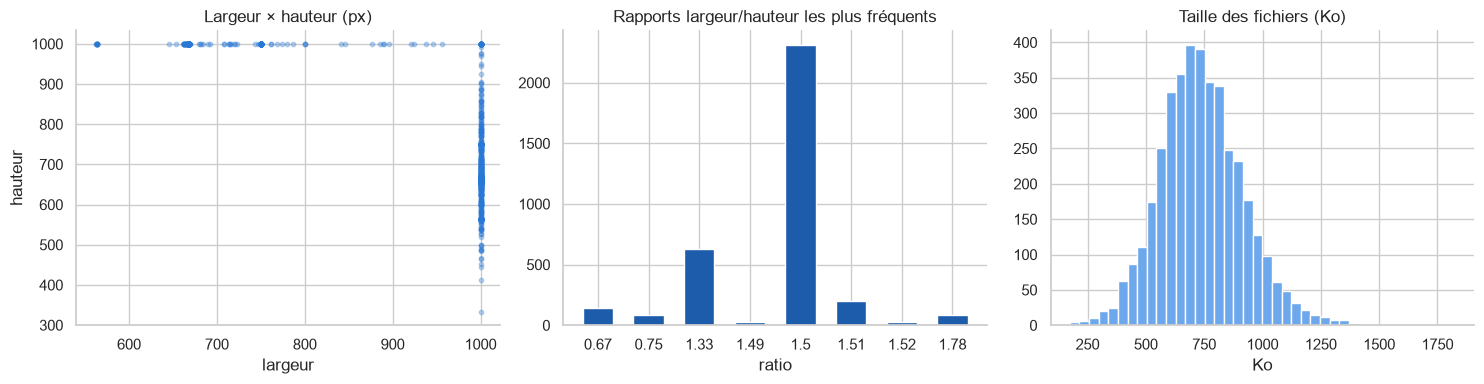

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(images["width"], images["height"], s=10, alpha=0.3, color="#2a78d6")
axes[0].set_title("Largeur × hauteur (px)"); axes[0].set_xlabel("largeur"); axes[0].set_ylabel("hauteur")
ratio = (images["width"] / images["height"]).round(2)
rc = ratio.value_counts().head(8).sort_index()
axes[1].bar(rc.index.astype(str), rc.values, color="#1c5cab", width=0.6)
axes[1].set_title("Rapports largeur/hauteur les plus fréquents"); axes[1].set_xlabel("ratio")
axes[2].hist(info["file_size_kb"], bins=40, color="#6da7ec", edgecolor="white")
axes[2].set_title("Taille des fichiers (Ko)"); axes[2].set_xlabel("Ko")
plt.tight_layout(); plt.show()

**Interprétation.**
- Les dimensions réelles de tous les fichiers correspondent aux JSON et toutes les images sont en **RGB / JPEG**.
- Les images ont été normalisées par les auteurs : le **plus grand côté vaut 1000 px** dans la grande majorité des cas ; la résolution dominante est 1000×667 (ratio 3:2), puis 1000×750 (4:3).
- Quelques centaines d'images sont en **portrait**.
- Comme la résolution d'origine est homogène, la taille apparente d'un dommage en pixels est comparable d'une image à l'autre. En revanche, les photos prises par un téléphone dans l'application auront une résolution différente : il faudra **redimensionner chaque région à une taille fixe** (phase 3), à l'entraînement comme à la prédiction.

## 9. Distribution des bounding boxes

In [16]:
bb = annotations
summary = bb.groupby("category_name").agg(
    n=("id", "size"),
    largeur_med=("bbox_w", "median"), hauteur_med=("bbox_h", "median"),
    surface_rel_med=("bbox_rel_area", "median"), ratio_med=("bbox_aspect_ratio", "median"),
).loc[CLASS_ORDER]
small = (bb["bbox_w"] < 32) | (bb["bbox_h"] < 32)
summary["pct_cote_lt_32px"] = (100 * small.groupby(bb["category_name"]).mean()).loc[CLASS_ORDER]
summary["remplissage_poly_med"] = (bb["area"] / bb["bbox_area_px"]).groupby(bb["category_name"]).median().loc[CLASS_ORDER]
display(summary.round(3))
print(f"Boîtes avec un côté < 32 px : {small.sum()} ; < 16 px : {((bb['bbox_w'] < 16) | (bb['bbox_h'] < 16)).sum()}")
print(f"Boîtes couvrant > 90 % de l'image : {(bb['bbox_rel_area'] > 0.9).sum()}")

,n,largeur_med,hauteur_med,surface_rel_med,ratio_med,pct_cote_lt_32px,remplissage_poly_med
category_name,,,,,,,
dent,2543,256.040,219.500,0.082,1.158,2.438,0.671
scratch,3595,247.420,166.180,0.056,1.474,3.755,0.563
crack,898,87.235,83.950,0.010,0.977,26.726,0.255
glass shatter,681,887.820,536.770,0.678,1.564,0.000,0.829
lamp broken,704,435.340,271.345,0.181,1.620,0.000,0.722
tire flat,319,477.610,491.430,0.347,1.058,0.000,0.806


Boîtes avec un côté < 32 px : 437 ; < 16 px : 96
Boîtes couvrant > 90 % de l'image : 176


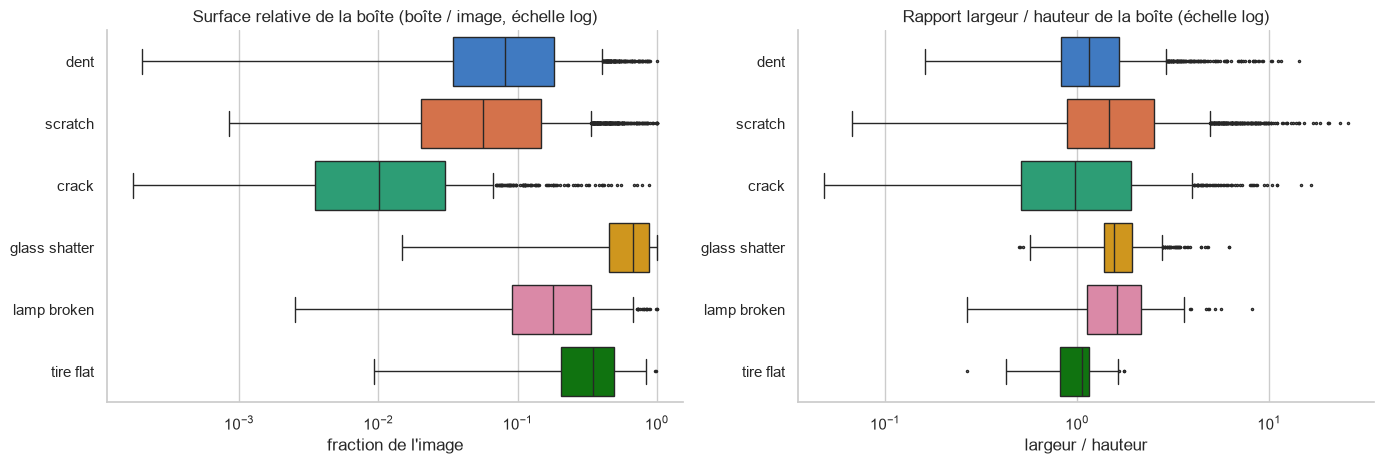

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=bb, x="bbox_rel_area", y="category_name", order=CLASS_ORDER, hue="category_name",
            palette=CLASS_COLORS, ax=axes[0], fliersize=1.5, linewidth=1, legend=False)
axes[0].set_xscale("log"); axes[0].set_title("Surface relative de la boîte (boîte / image, échelle log)")
axes[0].set_xlabel("fraction de l'image"); axes[0].set_ylabel("")
sns.boxplot(data=bb, x="bbox_aspect_ratio", y="category_name", order=CLASS_ORDER, hue="category_name",
            palette=CLASS_COLORS, ax=axes[1], fliersize=1.5, linewidth=1, legend=False)
axes[1].set_xscale("log"); axes[1].set_title("Rapport largeur / hauteur de la boîte (échelle log)")
axes[1].set_xlabel("largeur / hauteur"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

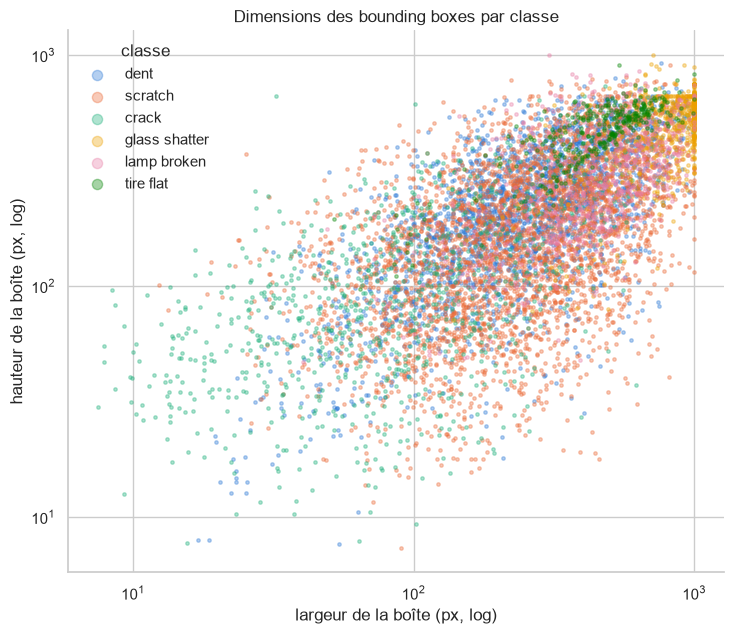

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for c in CLASS_ORDER:
    d = bb[bb["category_name"] == c]
    ax.scatter(d["bbox_w"], d["bbox_h"], s=6, alpha=0.35, color=CLASS_COLORS[c], label=c)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("largeur de la boîte (px, log)"); ax.set_ylabel("hauteur de la boîte (px, log)")
ax.set_title("Dimensions des bounding boxes par classe")
ax.legend(markerscale=3, frameon=False, title="classe")
plt.tight_layout(); plt.show()

**Interprétation.**
- La taille des régions dépend **fortement** de la classe : *glass shatter* couvre souvent la majorité de l'image (médiane ≈ 68 %), *tire flat* environ un tiers, tandis que *crack* est minuscule (médiane ≈ 1 % de l'image, ≈ 85 px de côté) et que plus d'un quart des fissures a un côté inférieur à 32 px.
- Les rapports largeur/hauteur sont dispersés (de très allongés à très hauts), surtout pour *scratch* et *crack*.
- Le « remplissage » (surface du polygone / surface de la boîte) est faible pour *crack* (≈ 0,26) : la boîte contient surtout de la carrosserie intacte autour d'une fissure fine. C'est un défi pour des descripteurs globaux.
- Implications pour la phase 3 :
  1. Redimensionner à taille fixe déforme les régions très allongées et **agrandit énormément** les petites fissures ; nous étudierons l'ajout d'une **marge de contexte** autour de la boîte et le redimensionnement avec conservation du ratio (padding).
  2. La taille de la boîte est un indice fort de la classe dans le dataset, mais **elle ne sera pas disponible de la même façon dans l'application** (l'utilisateur recadre lui-même) : nous ne l'utiliserons pas comme variable, pour éviter un modèle qui « triche ».
  3. Les boîtes très petites (< 16 px) seront examinées en phase 2 (nettoyage).

## 10. Métadonnées : angle de vue et couleur du véhicule

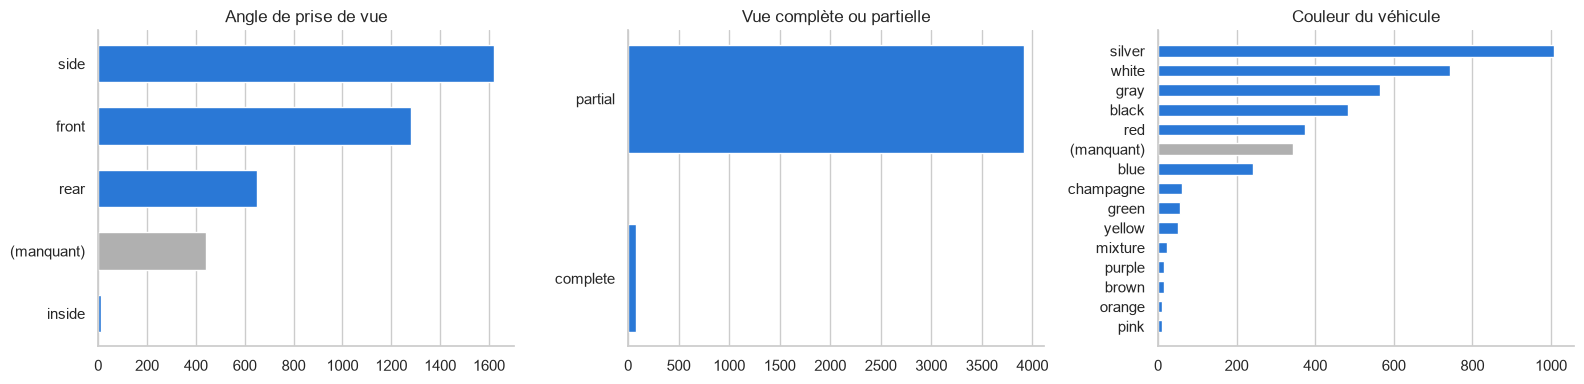

Répartition des angles de vue pour chaque classe (colonnes = 100 %) :


col_0,dent,scratch,crack,glass shatter,lamp broken,tire flat
shooting_angle,,,,,,
(manquant),0.05,0.13,0.12,0.04,0.05,0.01
front,0.28,0.28,0.51,0.71,0.48,0.06
inside,0.00,0.00,0.00,0.02,0.00,0.00
rear,0.19,0.11,0.20,0.08,0.36,0.02
side,0.48,0.47,0.18,0.15,0.12,0.92


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in [(axes[0], "shooting_angle", "Angle de prise de vue"),
                       (axes[1], "complete_or_partial", "Vue complète ou partielle"),
                       (axes[2], "color", "Couleur du véhicule")]:
    vc = info[col].fillna("(manquant)").value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1],
            color=["#b0b0b0" if i == "(manquant)" else "#2a78d6" for i in vc.index[::-1]], height=0.6)
    ax.set_title(title); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

angle_cls = pd.crosstab(
    annotations.merge(info[["id", "shooting_angle"]], left_on="image_id", right_on="id")["shooting_angle"].fillna("(manquant)"),
    annotations["category_name"].values, normalize="columns").round(2)
print("Répartition des angles de vue pour chaque classe (colonnes = 100 %) :")
angle_cls[CLASS_ORDER]

**Interprétation.**
- Les photos sont majoritairement prises de **côté** puis de **face** ; 98 % sont des **vues partielles** (gros plans), ce qui ressemble à l'usage prévu dans l'application (photo rapprochée du dommage).
- Les couleurs sont dominées par l'argent, le blanc, le gris et le noir : les histogrammes de couleur risquent donc de capter la **couleur de la carrosserie** plutôt que le dommage. Il faudra vérifier en phase 3 que les descripteurs de couleur apportent réellement quelque chose (par exemple en comparant HOG seul vs HOG + couleur).
- Ces métadonnées ne seront **pas** utilisées comme entrées du modèle (l'utilisateur ne les fournira pas), mais elles serviront à analyser les erreurs en phase 5.

## 11. Visualisation d'images annotées

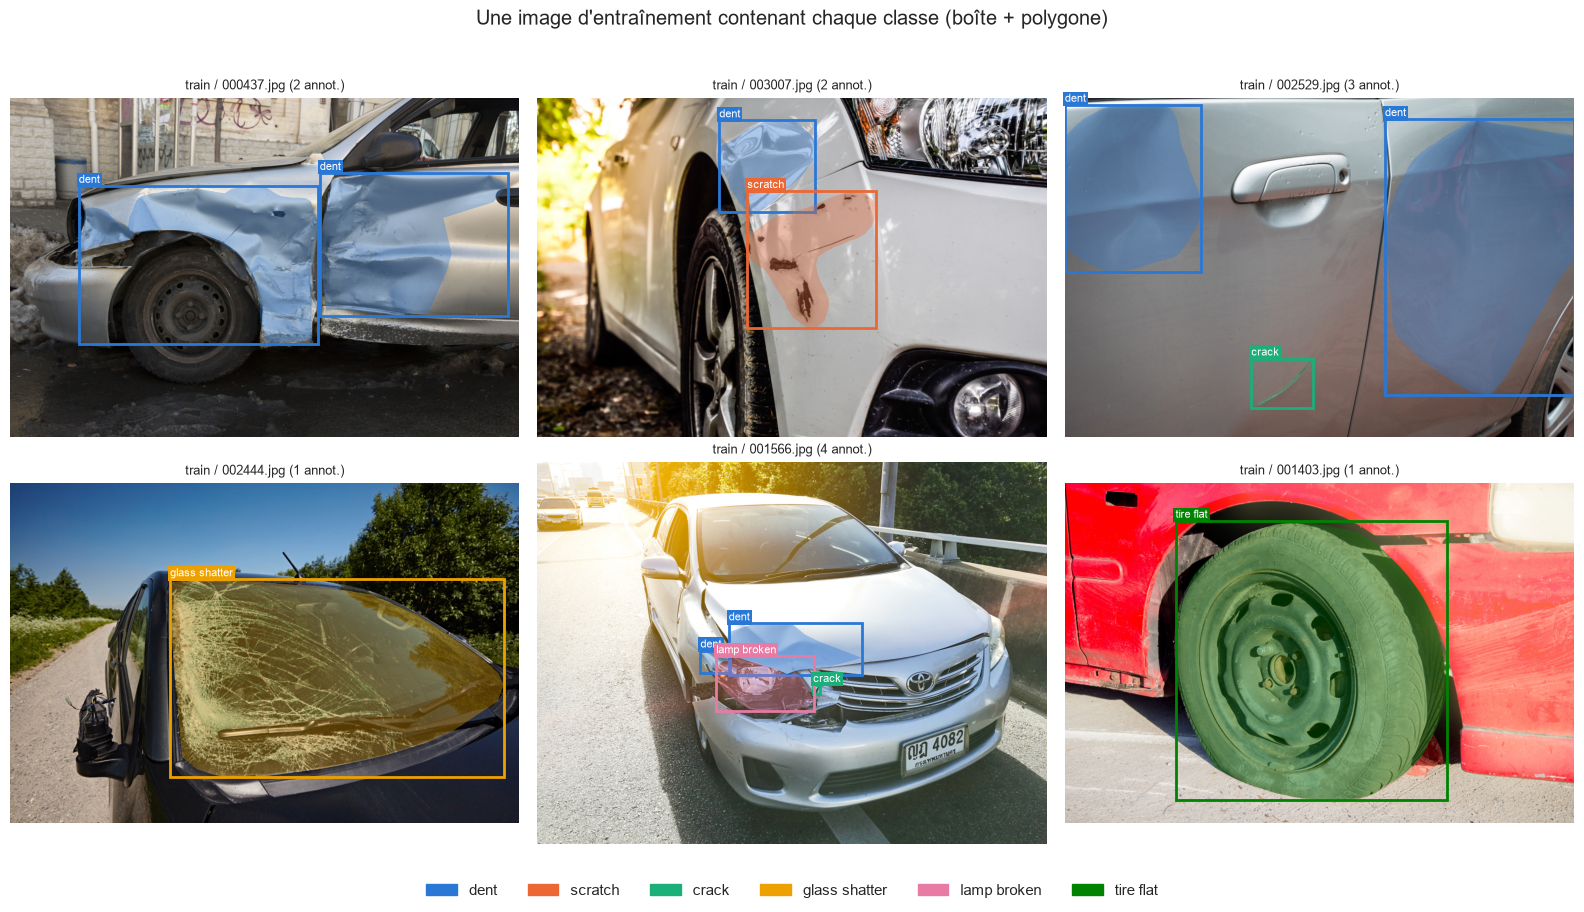

In [20]:
def show_annotated(ax, img_row, anns_img):
    img = read_image_rgb(image_dir(img_row["split"]) / img_row["file_name"])
    ax.imshow(img)
    for a in anns_img.itertuples():
        color = CLASS_COLORS[a.category_name]
        for poly in a.segmentation:
            pts = np.asarray(poly).reshape(-1, 2)
            ax.add_patch(mpatches.Polygon(pts, closed=True, facecolor=color, alpha=0.35, edgecolor="none"))
        ax.add_patch(mpatches.Rectangle((a.bbox_x, a.bbox_y), a.bbox_w, a.bbox_h, fill=False, edgecolor=color, linewidth=2))
        ax.text(a.bbox_x, a.bbox_y - 6, a.category_name, color="white", fontsize=8,
                bbox=dict(facecolor=color, edgecolor="none", pad=1.5))
    ax.set_title(f"{img_row['split']} / {img_row['file_name']} ({len(anns_img)} annot.)", fontsize=9)
    ax.axis("off")

rng = np.random.default_rng(42)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, cls in zip(axes.ravel(), CLASS_ORDER):
    cand = annotations[(annotations["category_name"] == cls) & (annotations["split"] == "train")]["image_id"].unique()
    img_id = rng.choice(cand)
    show_annotated(ax, images.set_index("id").loc[img_id].to_dict() | {"id": img_id},
                   annotations[annotations["image_id"] == img_id])
handles = [mpatches.Patch(color=CLASS_COLORS[c], label=c) for c in CLASS_ORDER]
fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False)
plt.suptitle("Une image d'entraînement contenant chaque classe (boîte + polygone)", y=1.0)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

**Interprétation.** Les polygones épousent le dommage tandis que la boîte est le rectangle englobant. On observe des boîtes qui se **chevauchent**
(par exemple une rayure à l'intérieur d'une bosse) : une région découpée pour une classe peut contenir une partie d'un autre dommage, ce qui créera une
ambiguïté naturelle entre *dent*, *scratch* et *crack*.

## 12. Aperçu des régions à classifier (crops des bounding boxes)

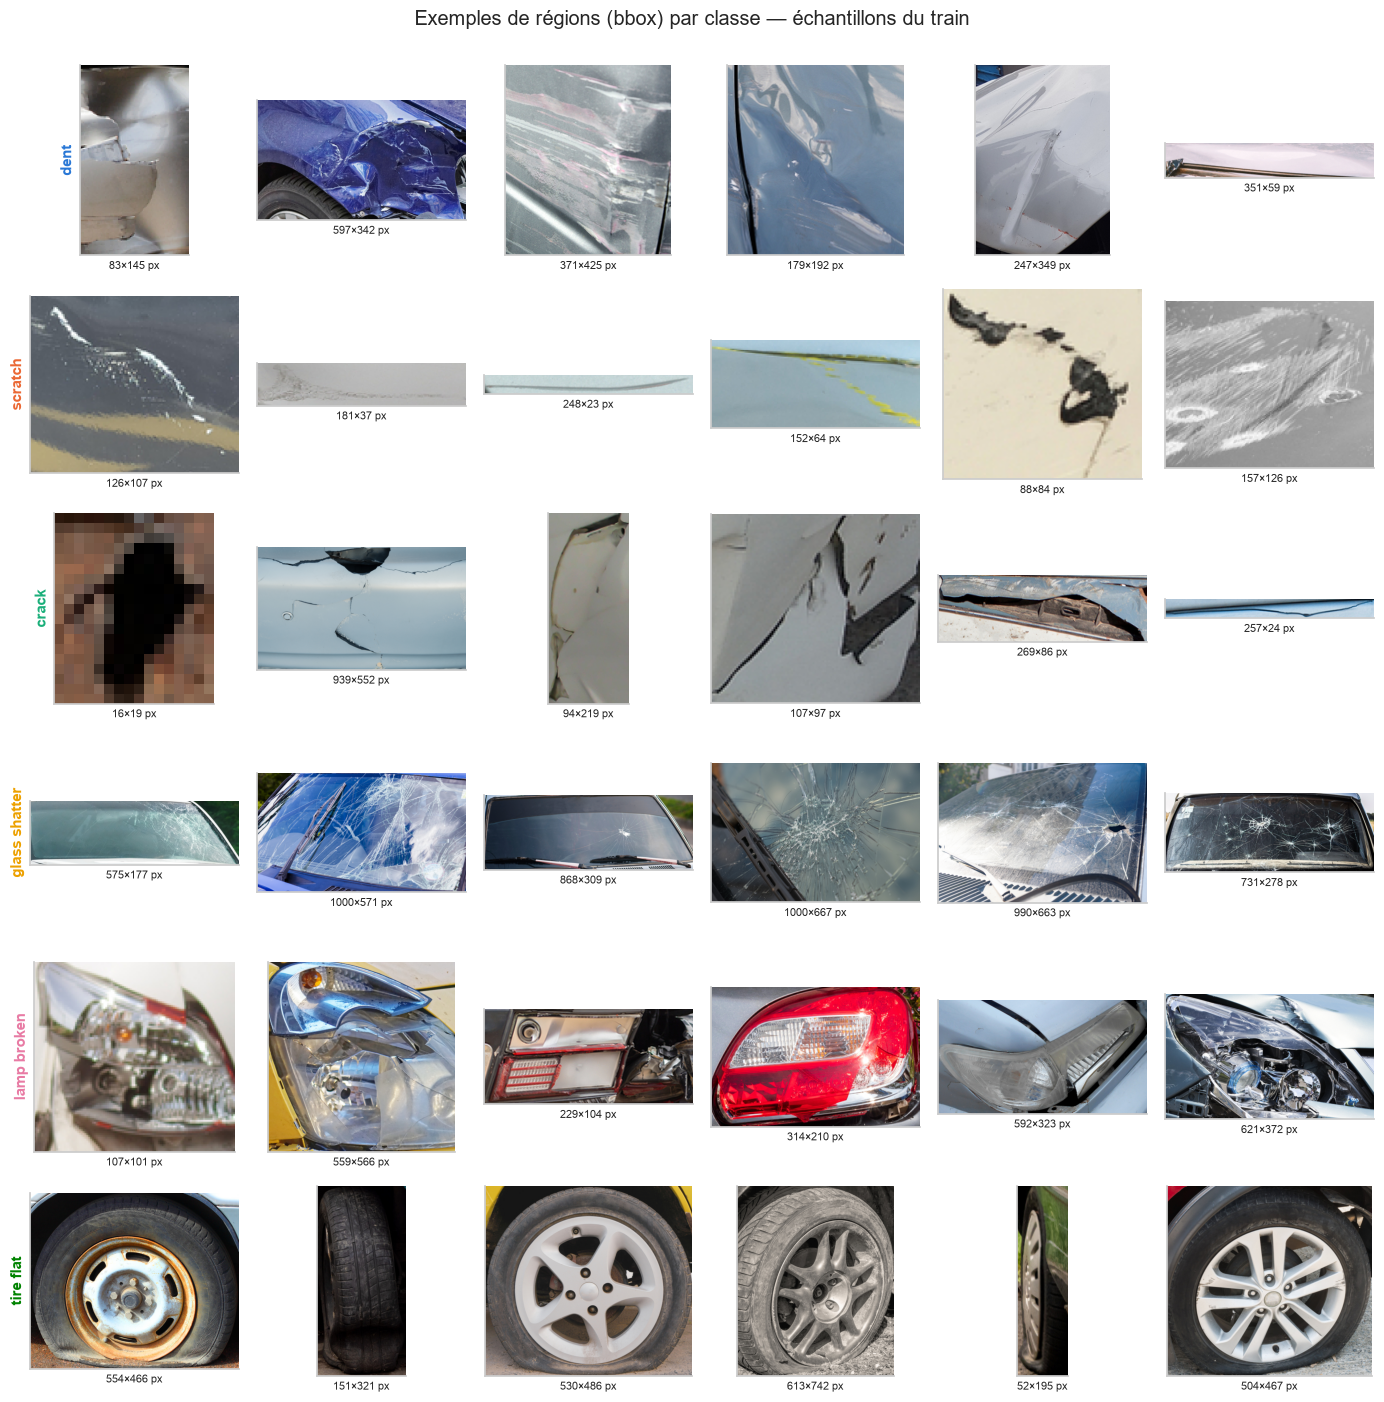

In [21]:
n_per_class = 6
fig, axes = plt.subplots(len(CLASS_ORDER), n_per_class, figsize=(14, 14))
rng = np.random.default_rng(0)
img_index = images.set_index("id")
for i, cls in enumerate(CLASS_ORDER):
    sub = annotations[(annotations["category_name"] == cls) & (annotations["split"] == "train")]
    for j, a in enumerate(sub.iloc[rng.choice(len(sub), n_per_class, replace=False)].itertuples()):
        r = img_index.loc[a.image_id]
        img = read_image_rgb(image_dir(r["split"]) / r["file_name"])
        x0, y0 = int(a.bbox_x), int(a.bbox_y)
        crop = img[y0:y0 + max(1, int(round(a.bbox_h))), x0:x0 + max(1, int(round(a.bbox_w)))]
        ax = axes[i, j]; ax.imshow(crop); ax.set_xticks([]); ax.set_yticks([])
        ax.set_xlabel(f"{crop.shape[1]}×{crop.shape[0]} px", fontsize=8)
        if j == 0:
            ax.set_ylabel(cls, fontsize=11, color=CLASS_COLORS[cls], fontweight="bold")
plt.suptitle("Exemples de régions (bbox) par classe — échantillons du train", y=1.0)
plt.tight_layout(); plt.show()

**Interprétation.** Ces régions sont exactement ce que le modèle recevra (après redimensionnement) et ce que l'utilisateur recadrera dans l'application.
- *glass shatter* (motif de fissures en étoile sur verre), *tire flat* (pneu déformé, formes sombres et arrondies) et *lamp broken* (optique, plastique transparent) ont une **apparence assez distinctive**.
- *dent*, *scratch* et *crack* se ressemblent davantage (carrosserie peinte avec reflets) et varient fortement en taille : on s'attend à ce que la majorité des confusions se produisent entre ces trois classes.
- La variabilité d'éclairage et de reflets est importante : les descripteurs de **forme/contours (HOG)** et de **texture** (par ex. LBP) sont des candidats naturels, à valider expérimentalement en phase 3.

## 13. Synthèse de la phase 1

| Constat | Conséquence pour la suite |
|---|---|
| Format COCO valide, 6 catégories identiques dans les 3 splits, xlsx cohérent avec les JSON | Base fiable ; le nettoyage (phase 2) vérifiera les cas limites |
| 4000 images, 8740 annotations, split ≈ 70/20/10 quasi stratifié | Échantillon = **une région annotée** ; on garde les splits officiels |
| Déséquilibre ≈ 11:1 (scratch vs tire flat) | **F1 macro** comme métrique principale, baseline `DummyClassifier`, test de `class_weight="balanced"` |
| Plusieurs classes par image dans ≈ 38 % des images | Classification de **régions recadrées**, pas d'images entières |
| Taille des boîtes très variable selon la classe ; fissures minuscules | Redimensionnement à taille fixe, étude d'une marge de contexte ; ne pas utiliser la taille de boîte comme variable |
| Images toutes RGB, plus grand côté ≈ 1000 px | Même lecture/conversion à l'entraînement et dans l'API (`src/data/image_io.py`) |
| Carrosseries majoritairement grises/blanches/noires | Vérifier l'apport réel des histogrammes de couleur |

**Points à traiter en phase 2 (nettoyage)** : boîtes très petites ou couvrant toute l'image, doublons exacts et quasi-doublons (notamment **entre splits**), fichiers corrompus, et validation fine des polygones.